In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris

In [3]:
iris = load_iris()

In [7]:
X = iris.data[:, :2]

In [8]:
y = iris.target

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [11]:
iris.feature_names[0:2]

['sepal length (cm)', 'sepal width (cm)']

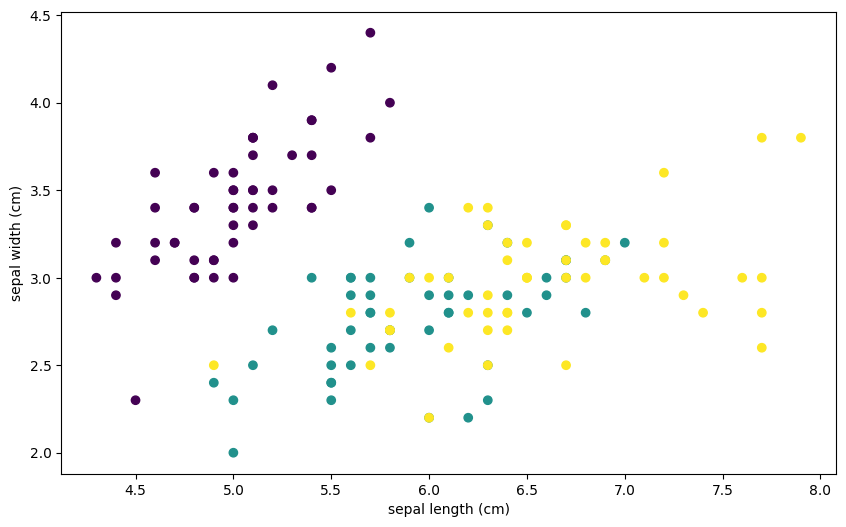

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c = y)
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.show()

In [15]:
from sklearn.tree import DecisionTreeClassifier

In [16]:
dt = DecisionTreeClassifier(max_depth= 2)

In [17]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [41]:
from sklearn.tree import plot_tree, export_text

[Text(0.5, 0.8333333333333334, 'sepal length (cm) <= 5.45\ngini = 0.667\nsamples = 120\nvalue = [40, 41, 39]\nclass = versicolor'),
 Text(0.25, 0.5, 'sepal width (cm) <= 2.8\ngini = 0.274\nsamples = 44\nvalue = [37, 6, 1]\nclass = setosa'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.449\nsamples = 7\nvalue = [1, 5, 1]\nclass = versicolor'),
 Text(0.375, 0.16666666666666666, 'gini = 0.053\nsamples = 37\nvalue = [36, 1, 0]\nclass = setosa'),
 Text(0.75, 0.5, 'sepal length (cm) <= 6.15\ngini = 0.536\nsamples = 76\nvalue = [3, 35, 38]\nclass = virginica'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.503\nsamples = 34\nvalue = [3, 22, 9]\nclass = versicolor'),
 Text(0.875, 0.16666666666666666, 'gini = 0.427\nsamples = 42\nvalue = [0, 13, 29]\nclass = virginica')]

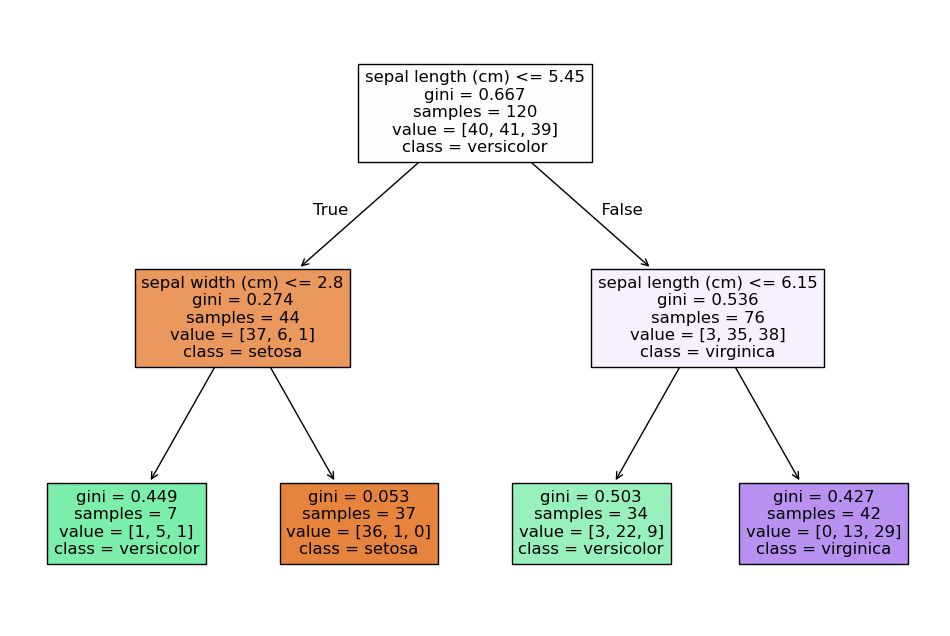

In [21]:
plt.figure(figsize=(12, 8))
plot_tree(dt, filled= True, feature_names= iris.feature_names[:2], class_names= iris.target_names)

In [22]:
y_pred = dt.predict(X_test)

In [23]:
from sklearn.metrics import accuracy_score

In [24]:
accuracy_score(y_test, y_pred)

0.8

In [26]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() -1, X[:, 1].max() + 1

In [27]:
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

In [37]:
z = dt.predict(np.c_[xx.ravel(), yy.ravel()])

In [38]:
z = z.reshape(xx.shape)

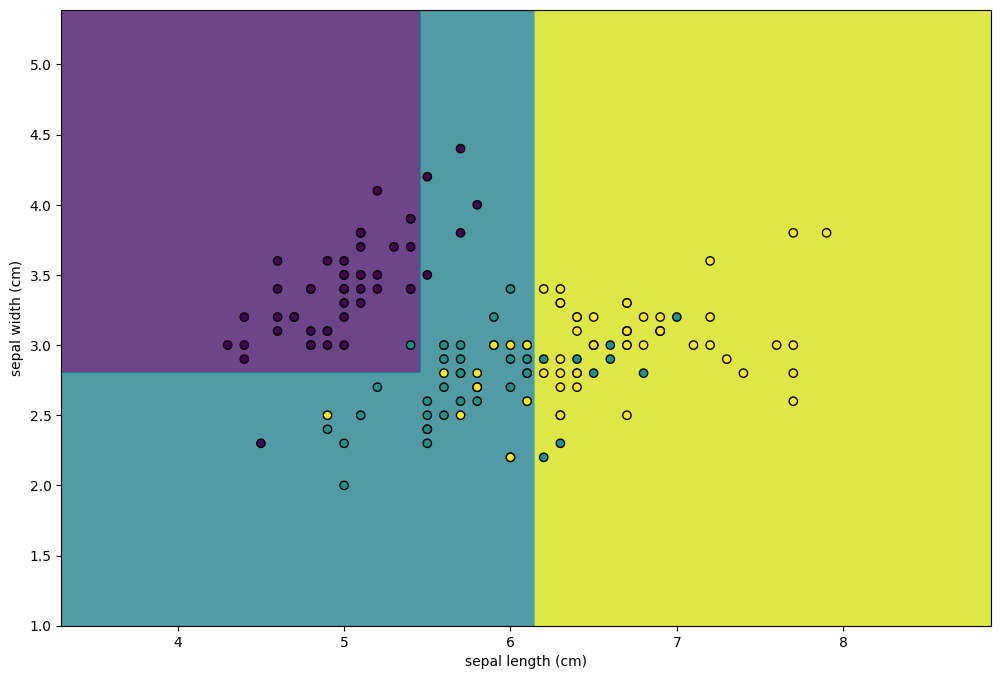

In [40]:
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, z, alpha = 0.8)
plt.scatter(X[:, 0], X[:, 1], c = y, edgecolors= 'k')
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.show()

In [45]:
r = export_text(dt, feature_names= iris.feature_names[:2], class_names= iris.target_names)

In [46]:
print(r)

|--- sepal length (cm) <= 5.45
|   |--- sepal width (cm) <= 2.80
|   |   |--- class: versicolor
|   |--- sepal width (cm) >  2.80
|   |   |--- class: setosa
|--- sepal length (cm) >  5.45
|   |--- sepal length (cm) <= 6.15
|   |   |--- class: versicolor
|   |--- sepal length (cm) >  6.15
|   |   |--- class: virginica



In [48]:
# to know the importance of features

In [49]:
dt.feature_importances_

array([0.8253173, 0.1746827])